<a href="https://colab.research.google.com/github/Mueez751/ozone-nonattainment-ml/blob/main/train%20model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load dataset
#url = "https://raw.githubusercontent.com/Mueez751/ozone-nonattainment-ml/main/ozone_county_features_labeled_2025.csv"

#df = pd.read_csv(url)

#df.head()
df = pd.read_csv("ozone_county_features_labeled_2025.csv")

# Select input features
features = [
    "ozone_daily_records",
    "mean_daily_ozone_ppm",
    "max_daily_ozone_ppm",
    "mean_daily_aqi",
    "mean_observation_percent"
]

X = df[features]
y = df["nonattainment_label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Define models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

# Train and evaluate
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    print(f"\n{name}")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

# Display comparison
results_df = pd.DataFrame(results)
print("\nMODEL COMPARISON")
print(results_df.round(3).to_string(index=False))


Logistic Regression
              precision    recall  f1-score   support

           0       0.92      0.81      0.86       121
           1       0.48      0.70      0.57        30

    accuracy                           0.79       151
   macro avg       0.70      0.75      0.71       151
weighted avg       0.83      0.79      0.80       151

Confusion Matrix:
[[98 23]
 [ 9 21]]

Decision Tree
              precision    recall  f1-score   support

           0       0.89      0.83      0.86       121
           1       0.47      0.60      0.53        30

    accuracy                           0.79       151
   macro avg       0.68      0.72      0.70       151
weighted avg       0.81      0.79      0.80       151

Confusion Matrix:
[[101  20]
 [ 12  18]]

Random Forest
              precision    recall  f1-score   support

           0       0.89      0.89      0.89       121
           1       0.55      0.53      0.54        30

    accuracy                           0.82       151

In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

log_model = models["Logistic Regression"]
probs = log_model.predict_proba(X_test)[:, 1]

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
rows = []

for t in thresholds:
    preds = (probs >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1-score": f1_score(y_test, preds, zero_division=0),
    })

threshold_df = pd.DataFrame(rows)
print(threshold_df.round(3).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.30      0.316   0.833     0.459
      0.35      0.369   0.800     0.505
      0.40      0.421   0.800     0.552
      0.45      0.429   0.700     0.532
      0.50      0.477   0.700     0.568
      0.55      0.500   0.667     0.571
      0.60      0.571   0.667     0.615


In [10]:
from sklearn.metrics import confusion_matrix, classification_report

# Use the threshold with the highest F1 in your results
best_threshold = 0.60

y_pred_060 = (
    log_model.predict_proba(X_test)[:, 1] >= best_threshold
).astype(int)

print("Confusion Matrix (threshold = 0.60):")
print(confusion_matrix(y_test, y_pred_060))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_060, zero_division=0
))

Confusion Matrix (threshold = 0.60):
[[106  15]
 [ 10  20]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.89       121
           1       0.57      0.67      0.62        30

    accuracy                           0.83       151
   macro avg       0.74      0.77      0.75       151
weighted avg       0.85      0.83      0.84       151



In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Logistic Regression pipeline
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    }
)

print("5-Fold Cross-Validation Results")
# print("--------------------------------")

for metric in ["accuracy", "precision", "recall", "f1"]:
    values = scores[f"test_{metric}"]
    print(
        f"{metric.capitalize():10s}: "
        f"{values.mean():.3f} ± {values.std():.3f}"
    )

5-Fold Cross-Validation Results
--------------------------------
Accuracy  : 0.781 ± 0.022
Precision : 0.476 ± 0.030
Recall    : 0.770 ± 0.021
F1        : 0.588 ± 0.028


In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_cv = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

results = []

for name, model in models_cv.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean()
    })

comparison = pd.DataFrame(results)
print(comparison.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression     0.781      0.476   0.770     0.588
      Decision Tree     0.818      0.554   0.533     0.542
      Random Forest     0.871      0.737   0.566     0.638


Random Forest - New Test Split
--------------------------------
Accuracy: 0.801

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.87      0.88       121
           1       0.50      0.53      0.52        30

    accuracy                           0.80       151
   macro avg       0.69      0.70      0.70       151
weighted avg       0.81      0.80      0.80       151

Confusion Matrix:
[[105  16]
 [ 14  16]]


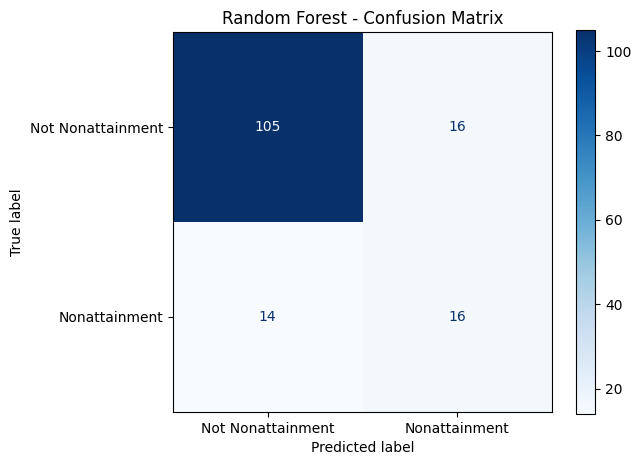

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# new 80/20 split (different seed from the first one)
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X, y, test_size=0.20, random_state=2026, stratify=y
)

# train the random forest
rf_final = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf_final.fit(X_train_final, y_train_final)

# predict on the test set
y_pred_final = rf_final.predict(X_test_final)

# results
print("Random Forest - New Test Split")
print("-" * 32)
print("Accuracy:", round(accuracy_score(y_test_final, y_pred_final), 3))

print("\nClassification Report:")
print(classification_report(y_test_final, y_pred_final, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test_final, y_pred_final))

# confusion matrix plot
ConfusionMatrixDisplay.from_predictions(
    y_test_final, y_pred_final,
    display_labels=["Not Nonattainment", "Nonattainment"],
    cmap="Blues"
)
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()




importances = pd.Series(rf_final.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh")
plt.title("Random Forest - Feature Importance")
plt.tight_layout()
plt.show()